## 투자자의 위험 감수 성향과 로보어드바이저
* 투자자의 위험 감수 성향 또는 위험 회피 성향을 예측하는 머신러닝 모델
    * 동일한 가구의 2007년(금융위기 이전)과 2009년(금융위기 이후) 인구통계학적 특성, 순자산, 금융자산 및 비금융자산 정보가 포함
* Data
    * SCFP2009panel.xlsx : 소비자금융조사 데이터셋
    * SP500Data.csv : 미국 S&P 500 기업의 주식 가격 데이터

## 패키지 불러오기

In [27]:
import numpy as np
import pandas as pd
import pandas_datareader.data as web
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
import seaborn as sns
import copy 
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neural_network import MLPRegressor


In [28]:
import warnings
warnings.filterwarnings('ignore')

## 데이터 불러오기

In [29]:
# 미국 가계 금융조사(Survey of Consumer Finances, SCF)의 2007~2009년 패널 데이터셋
    #  패널 데이터 셋 : 동일한 가구를 시간의 흐름에 따라 다시 조사한 데이터
# 미국 연방준비제도(Federal Reserve Board)가 조사한 가구별 금융자산, 부채, 소득, 순자산 및 인구통계 정보
dataset = pd.read_excel('./data/SCFP2009panel.xlsx')

In [30]:
type(dataset)

pandas.core.frame.DataFrame

In [31]:
dataset.shape

(19285, 515)

## 데이터 준비와 특성 선택
* 소비자금융조사 데이터셋에는 동일한 가구의 2007년(금융위기 이전)과 2009년(금융위기 이후) 인구통계학적 특성, 순자산, 금융자산 및 비금융자산 정보가 포함
* 예측 대상 변수인 실제 위험 감수 성향을 계산
* 실제 위험 감수 성향을 추정하는 방법은 다양 : 머신러닝으로 행동재무학 문제를 해결하는 접근 방식을 제시
    * 행동재무학
        * 투자자의 비합리적인 의사결정 패턴을 데이터로 발견하고, 미래의 금융 행동을 예측하여 더 합리적인 의사결정을 지원하는 것
        * 전통적인 금융이론은 투자자가 합리적으로 의사결정한다고 가정하지만, 행동재무학은 인간의 심리적 편향이 금융 의사결정에 영향을 미친다고 봅니다.
        * 1. 행동재무학의 주요 문제 정의
            * 행동재무학      /             이론	주요 문제	   /     머신러닝 활용 방향
            * 손실회피(Loss Aversion)  /	손실을 이익보다 크게 인식	/ 손실 상황에서의 자산 변화 패턴 분석
            * 과신(Overconfidence)  /	자신의 투자 능력을 과대평가	/ 과도한 투자 집중 및 레버리지 패턴 탐색
            * 군집행동(Herd Behavior)  /	다른 투자자를 따라 투자	 / 투자 행태의 유사성 및 동조 패턴 분석
            * 처분효과(Disposition Effect)	 / 이익은 빨리 실현하고 손실은 오래 보유  /	매매 이력에서 이익·손실 실현 차이 분석
            * 현상유지편향(Status Quo Bias)	/  기존 금융 상태를 쉽게 변경하지 않음  /	자산 구성의 변화 여부 분석
            * 현재편향(Present Bias)	  / 미래보다 현재 소비를 중시  /	저축률과 부채 구조 분석

    * 중요한 점은 SCF 데이터만으로 투자자의 심리 상태를 직접 관측할 수는 없다는 것입니다. 따라서 금융 행동을 심리적 편향의 대리변수(Proxy Variable)로 활용해야 합니다.

* 예측 대상 변수의 계산 절차
1. 조사 대상자별로 위험자산과 무위험자산을 계산
    * 위험자산: 뮤추얼펀드, 주식, 채권, 원자재, 부동산에 대한 투자 및 인적자본의 추정치
    * 무위험자산: 당좌예금과 저축예금 잔액, 양도성예금증서, 기타 현금 및 현금성 자산

2. 투자자의 전체 자산 중 위험자산이 차지하는 비율을 위험 감수 성향의 지표로 사용
    * SCF 데이터의 2007년과 2009년 위험자산·무위험자산 정보를 사용
    * 두 시점의 주가지수 수준을 반영하여 위험 감수 성향을 조정
    * 위험 감수 성향 : 위험자산을 위험자산과 무위험자산의 합으로 나눈 비율을 사용
    * 2009년 값에는 2007년 대비 2009년 S&P 500 평균 지수 비율을 곱함
    * 2007년 S&P 500 평균 지수: 1478
    * 2009년 S&P 500 평균 지수: 948

3. 시장 변화에도 위험 감수 성향을 크게 바꾸지 않는 사람을 '현명한 투자자'로 가정 
    * 2007년과 2009년 사이에 위험 감수 성향의 변화가 10% 미만인 투자자를 이 범주로 분류 : 정성적인 가정이며 변경할 수 있음
    * 정확한 투자자 분류 자체보다는 머신러닝 활용 방법을 보여 주고, 행동재무학 및 포트폴리오 관리의 추가 분석에 활용할 수 있는 틀을 제공

* 무엇을 하려고 하나?
    * 현명한 투자자들을 대상으로 위험감수성향(Risk Tolerance)를 예측
    * ex) A: 자산 대부분을 주식이나 부동산에 투자함. B: 자산 대부분을 예금이나 현금으로 보유함.
        * 문제 A가 B보다 위험을 더 많이 감수하는 사람이라고 볼 수 있음. 위험 감수에 대한 정량적인 값을 관측하기 어려움 
        * 그래서 Y를 직접 만듬
* 위험 감수 성향 계산
    * 자산 중 위험자산이 차지하는 비중을 위험 감수 성향의 대리 지표로 사용함
    * RT = 위험자산 / (위험자산 + 무위험자산)
    * 총 자산 1억원, 위험자산 6천만원, 무위험자산 4천만원 : RT = 0.6(위험 감수 성향)
    * 문제점 : 실제 심리적 위험 감수 성향을 정확히 측정한 수치가 아님
        * 2007년과 2009년의 S&P 500지수를 반영해서 시장 가격 변화의 영향을 보정

* 2007년과 2009년의 위험 감수 성향(Risk Tolerance, RT)를 계산

In [32]:
Average_SP500_2007=1478
Average_SP500_2009=948

# 2007년의 위험 감수 성향 계산
# 무위험 자산 (RiskFree) : 유동성 자산(예금 계좌 등) + 양도성 예금증서 + 저축성 채권 + 현금 가치 생명보험 
dataset['RiskFree07']= dataset['LIQ07'] + dataset['CDS07'] + dataset['SAVBND07'] + dataset['CASHLI07'] 
# 위험 자산 (Risky) : NMMF(머니마켓펀드를 제외한 뮤추얼펀드) + 주식 + 채권
dataset['Risky07'] = dataset['NMMF07'] + dataset['STOCKS07'] + dataset['BOND07'] 
# 위험 감수 성향 (RT) = 위험 자산 ÷ (위험 자산 + 무위험 자산) : 금융자산 중 위험 자산이 차지하는 비중. 
# 0에 가까우면 보수적, 1에 가까우면 공격적인 투자자
dataset['RT07'] = dataset['Risky07']/(dataset['Risky07']+dataset['RiskFree07'])

# 2009년의 위험 감수 성향 계산
dataset['RiskFree09']= dataset['LIQ09'] + dataset['CDS09'] + dataset['SAVBND09'] + dataset['CASHLI09']
dataset['Risky09'] = dataset['NMMF09'] + dataset['STOCKS09'] + dataset['BOND09'] 
# 계산 방식은 2007년과 같지만, 끝에 **시장 지수 변화율(1478/948 ≈ 1.56)**을 곱함
dataset['RT09'] = dataset['Risky09']/(dataset['Risky09']+dataset['RiskFree09'])*\
                (Average_SP500_2007/Average_SP500_2009)

'''
= 보정값을 2009년에 반영하는 이유
  2009년에는 주가가 폭락해서, 투자자가 아무것도 하지 않아도 위험 자산 비중이 자연스럽게 줄어줌
  단순 비중만 비교하면 "투자자가 겁을 먹어서 비중을 줄였는지" 아니면 "시장이 떨어져서 비중이 줄어 보이는 건지" 구분하기 어려
  이 보정은 시장 변동을 감안해 투자자의 실제 행동 변화를 더 잘 반영하려는 시도
'''

'\n= 보정값을 2009년에 반영하는 이유\n  2009년에는 주가가 폭락해서, 투자자가 아무것도 하지 않아도 위험 자산 비중이 자연스럽게 줄어줌\n  단순 비중만 비교하면 "투자자가 겁을 먹어서 비중을 줄였는지" 아니면 "시장이 떨어져서 비중이 줄어 보이는 건지" 구분하기 어려\n  이 보정은 시장 변동을 감안해 투자자의 실제 행동 변화를 더 잘 반영하려는 시도\n'

In [33]:
dataset2 = copy.deepcopy(dataset)   # 파이썬 표준 라이브러리 방식
dataset.head()

,YY1,Y1,WGT09,AGE07,AGECL07,EDUC07,EDCL07,MARRIED07,KIDS07,LIFECL07,...,TRANSFOTHINCPCT,PSAVINGPCT,LEVERAGEPCT,I,RiskFree07,Risky07,RT07,RiskFree09,Risky09,RT09
0,1,11,11668.134198,47,3,12,2,1,0,2,...,0.0,93.125197,270.403054,57,7994.813847,0.0,0.0,16000,17000,0.803158
1,1,12,11823.456494,47,3,12,2,1,0,2,...,0.0,93.125197,249.593620,57,7994.813847,0.0,0.0,19000,18000,0.758467
2,1,13,11913.228354,47,3,12,2,1,0,2,...,0.0,93.125197,209.233358,57,7984.457871,0.0,0.0,13000,12000,0.748354
3,1,14,11929.394266,47,3,12,2,1,0,2,...,0.0,93.125197,209.273158,57,7984.457871,0.0,0.0,25000,13000,0.533367
4,1,15,11917.722907,47,3,12,2,1,0,2,...,0.0,93.125197,232.690767,57,7994.813847,0.0,0.0,17000,12000,0.645133


* 2007년과 2009년 사이의 위험 감수 성향 변화율을 계산

In [34]:
# 절대값 : 증가인지 감소인지는 상관없이 변화의 크기만 보려는 것입
dataset2['PercentageChange'] = np.abs(dataset2['RT09']/dataset2['RT07']-1)

In [35]:
# 결측값이 있는지 확인
print('Null Values =',dataset2.isnull().values.any())

Null Values = True


In [36]:
# 결측값(NA)이 포함된 행 제거
dataset2=dataset2.dropna(axis=0) # 행(row) 방향으로 삭제, NaN만 제거, inf는 남음

# isin([...])로 각 셀이 NaN, inf, -inf인지 검사하고
# .any(axis=1)로 그런 값이 하나라도 있는 행을 찾은 뒤
# ~로 뒤집어서 문제 값이 없는 행만 남김
dataset2=dataset2[~dataset2.isin([np.nan, np.inf, -np.inf]).any(axis=1)] # 한 번에 필터링

print('Null Values =',dataset2.isnull().values.any())

Null Values = False


* 2007년과 2009년의 위험 감수 성향 분포를 시각화

'   \n0 근처에 막대가 몰려 있음: 위험자산을 거의 갖지 않는 보수적 가구가 많다는 뜻\n1 근처에 막대가 몰려 있음: 거의 전부를 위험자산에 넣은 공격적 가구가 많다는 뜻\n\n= 해석 :\n2007년의 위험 감수 성향을 보면 상당수 투자자의 값이 1에 있음\n무위험자산보다 위험자산에 더 많은 자산을 투자했음\n'

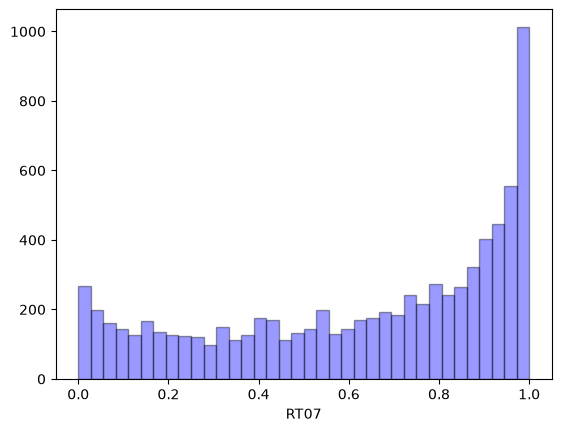

In [37]:
# 2007년 위험 감수 성향 분포
sns.distplot(dataset2['RT07'], hist=True, kde=False, 
             bins=int(180/5), color = 'blue',
             hist_kws={'edgecolor':'black'})

'''   
0 근처에 막대가 몰려 있음: 위험자산을 거의 갖지 않는 보수적 가구가 많다는 뜻
1 근처에 막대가 몰려 있음: 거의 전부를 위험자산에 넣은 공격적 가구가 많다는 뜻

= 해석 :
2007년의 위험 감수 성향을 보면 상당수 투자자의 값이 1에 있음
무위험자산보다 위험자산에 더 많은 자산을 투자했음
'''

'   \n= 해석\n금융위기 이후인 2009년에는 투자자들의 행동이 반대로 바뀌어 대부분의 투자가 무위험자산에 집중\n2009년의 위험 감수 성향 값이 대부분 0에 가까운 것을 통해 전반적인 위험 감수 성향이 감소했음을 확인\n'

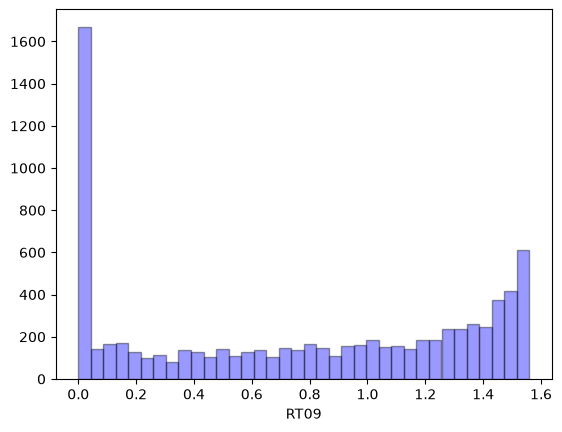

In [38]:
# 2009년 위험 감수 성향 분포
sns.distplot(dataset2['RT09'], hist=True, kde=False, 
             bins=int(180/5), color = 'blue',
             hist_kws={'edgecolor':'black'})

'''   
= 해석
금융위기 이후인 2009년에는 투자자들의 행동이 반대로 바뀌어 대부분의 투자가 무위험자산에 집중
2009년의 위험 감수 성향 값이 대부분 0에 가까운 것을 통해 전반적인 위험 감수 성향이 감소했음을 확인
'''

* 현명한 투자자 추출 : 위험 감수 성향의 변화율이 10% 이하인 투자자만 선택

In [39]:
# 투자자를 선별하기 위한 데이터 복사본
dataset3 = copy.deepcopy(dataset2)  
dataset3 = dataset3[dataset3['PercentageChange']<=.1]

* 위험 감수 성향 평균을 예측 대상 변수로 설정

In [40]:
dataset3['TrueRiskTolerance'] = (dataset3['RT07'] + dataset3['RT09'])/2

* 중간 계산에 사용한 위험 감수 성향과 변화율 열을 제거

In [41]:
dataset3.drop(labels=['RT07', 'RT09'], axis=1, inplace=True)
dataset3.drop(labels=['PercentageChange'], axis=1, inplace=True)

* 예측에 사용할 특성과 예측 대상 변수

In [42]:
keep_list2 = ['AGE07','EDCL07','MARRIED07','KIDS07','OCCAT107','INCOME07','RISK07','NETWORTH07','TrueRiskTolerance'
]  
# = 입력 필드
    # 연령
    # 학력 수준 : 1은 고졸 미만, 2는 고졸 또는 GED, 3은 대학 교육 경험이 있으나 대학 학위를 취득하지 않은 경우, 4는 대학 학위 취득
    # 결혼/동거 상태 : 1은 결혼했거나 파트너와 동거 중인 경우, 2는 둘 다 아닌 경우
    # 자녀수 : 친자녀뿐 아니라 의붓자녀·위탁자녀 관계도 포함
    # 고용/경제활동 상태 : 1은 타인에게 고용된 근로자, 2는 자영업·파트너십, 3은 은퇴·장애 및 일부 65세 이상 비취업자, 4는 기타 비취업자
    # 가구 연간 총소득 : 개인 월급이 아니라 가구 전체의 연간 소득, 기준 달러 
    # 설문으로 응답한 금융 위험 선호도 : 1은 높은 수익을 기대하며 상당한 위험을 감수, 2는 평균 이상의 위험을 감수, 
                                    # 3은 평균 수준의 위험을 감수, 4는 금융 위험을 원하지 않는 경우
                                    # 숫자가 작을수록 공격적인 성향
    # 가구 순자산 : 총자산 − 총부채, 예금뿐 아니라 주택·사업자산 등도 포함하는 개념
# = 출력 필드 
    # 예제에서 계산한 위험감내 성향 대리값

In [43]:
drop_list2 = [col for col in dataset3.columns if col not in keep_list2]
dataset3.drop(labels=drop_list2, axis=1, inplace=True)

In [44]:
drop_list2

['YY1',
 'Y1',
 'WGT09',
 'AGECL07',
 'EDUC07',
 'LIFECL07',
 'FAMSTRUCT07',
 'RACECL',
 'H_RACECL',
 'RACE',
 'H_RACE',
 'OCCAT207',
 'INDCAT07',
 'HHEALTH07',
 'SPHEALTH07',
 'WAGEINC07',
 'BUSSEFARMINC07',
 'INTDIVINC07',
 'KGINC07',
 'SSRETINC07',
 'TRANSFOTHINC07',
 'PENACCTWD07',
 'NORMINC07',
 'PSAVING07',
 'WSAVED07',
 'SAVED07',
 'SAVRES1',
 'SAVRES2',
 'SAVRES3',
 'SAVRES4',
 'SAVRES5',
 'SAVRES6',
 'SAVRES7',
 'SAVRES8',
 'SAVRES9',
 'SPENDMOR07',
 'LATE6007',
 'USPELL07',
 'AGEFT07',
 'AGEALL07',
 'POSTRWORK07',
 'RFULL07',
 'BSHOPNONE07',
 'BSHOPGRDL07',
 'BSHOPMODR07',
 'ISHOPNONE07',
 'ISHOPGRDL07',
 'ISHOPMODR07',
 'BCALL07',
 'BMAGZNEWS07',
 'BMAILADTV07',
 'BINTERNET07',
 'BFRIENDWORK07',
 'BFINPRO07',
 'BSELF07',
 'BDONT07',
 'BOTHER07',
 'ICALL07',
 'IMAGZNEWS07',
 'IMAILADTV07',
 'IINTERNET07',
 'IFRIENDWORK07',
 'IFINPRO07',
 'ISELF07',
 'IDONT07',
 'IOTHER07',
 'BFINPLAN07',
 'IFINPLAN07',
 'APPLIED07',
 'DENIED07',
 'FULLAMT07',
 'FEARED07',
 'CHECKING07',
 'HCH

* 특성 간의 상관관계

'\nRISK07이 TrueRiskTolerance와 높은 상관을 보일 것이라고 생각 했는데, 실제로는 0.02로 사실상 상관이 없음. 예상이 틀림\n선형 모델은 성능이 제한적일 가능성 큼, 타깃과의 상관이 모두 낮음. 다만 상관이 낮다고 쓸모없는 변수는 아님\n'

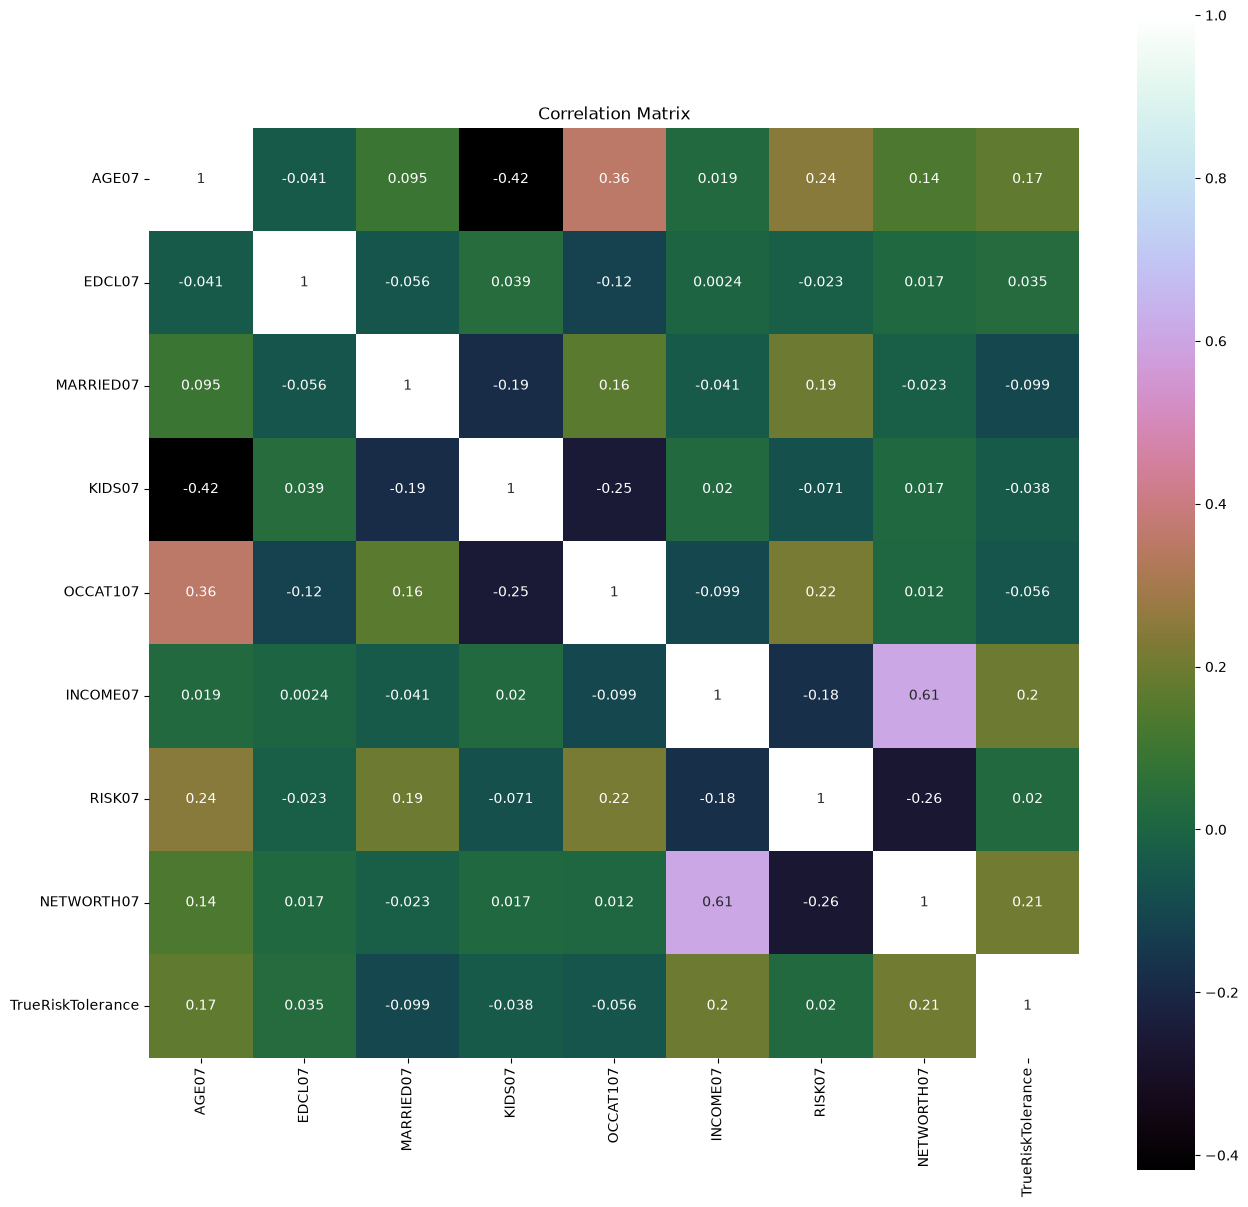

In [45]:
correlation = dataset3.corr()
plt.figure(figsize=(15,15))
plt.title('Correlation Matrix')
sns.heatmap(correlation, vmax=1, square=True,annot=True,cmap='cubehelix')# 색상 척도의 최댓값을 1로 고정
'''
RISK07이 TrueRiskTolerance와 높은 상관을 보일 것이라고 생각 했는데, 실제로는 0.02로 사실상 상관이 없음. 예상이 틀림
선형 모델은 성능이 제한적일 가능성 큼, 타깃과의 상관이 모두 낮음. 다만 상관이 낮다고 쓸모없는 변수는 아님
피어슨 상관은 선형 관계만 보므로 선형 모델을 사용 할경우 성능이 안나올 수 있음
비선형 모델을 사용할 필요가 있음
RISK07이 TrueRiskTolerance의 자기 평가 값임에도 불구하고 관계가 낮게 나옴
'''

<Figure size 1500x1500 with 0 Axes>

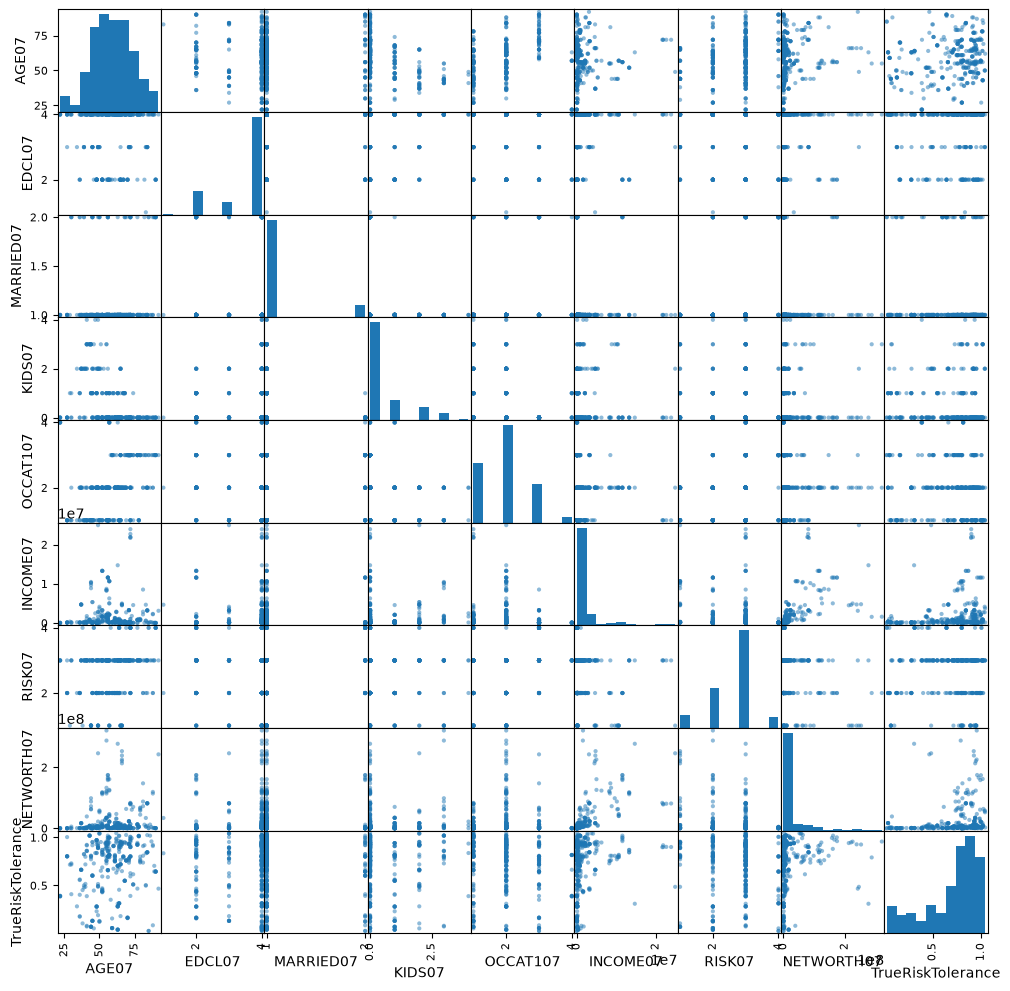

In [46]:
# 산점도 행렬 그리기
from pandas.plotting import scatter_matrix
plt.figure(figsize=(15,15))
scatter_matrix(dataset3,figsize=(12,12))
plt.show()

In [47]:
plt.savefig("scatter_matrix.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## 알고리즘과 모델 평가

* 학습·테스트 데이터 분리

In [48]:
Y= dataset3["TrueRiskTolerance"]
X = dataset3.loc[:, dataset3.columns != 'TrueRiskTolerance']

validation_size = 0.2
seed = 3
X_train, X_validation, Y_train, Y_validation = train_test_split(X, Y, test_size=validation_size,\
                                                                random_state=seed)

* 평가 설정과 평가 지표

In [49]:
num_folds = 10

#scoring = 'neg_mean_squared_error' 
scoring = 'r2'

* 모델과 알고리즘 비교 -  회귀 모델

In [50]:
models = []
models.append(('LR', LinearRegression()))
models.append(('LASSO', Lasso()))
models.append(('EN', ElasticNet()))
models.append(('KNN', KNeighborsRegressor()))
models.append(('CART', DecisionTreeRegressor()))
models.append(('SVR', SVR()))
# 신경망 모델
# models.append(('MLP', MLPRegressor()))
# 앙상블 모델
# 부스팅 방식의 앙상블 모델
models.append(('ABR', AdaBoostRegressor()))
models.append(('GBR', GradientBoostingRegressor()))
# 배깅 방식의 앙상블 모델
models.append(('RFR', RandomForestRegressor()))
models.append(('ETR', ExtraTreesRegressor()))

* K-폴드 교차 검증

In [51]:
results = []
names = []
for name, model in models:
    kfold = KFold(n_splits=num_folds)

    # scoring = neg_mean_squared_error' 일 경우 return값에 -1을 곱해줌
    cv_results = cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

LR: -0.003328 (0.129598)
LASSO: -0.003328 (0.129598)
EN: 0.004757 (0.132965)
KNN: 0.338639 (0.256047)
CART: 0.484604 (0.308434)
SVR: 0.038124 (0.128636)
ABR: 0.435773 (0.138096)
GBR: 0.605761 (0.185618)
RFR: 0.632790 (0.191666)
ETR: 0.713836 (0.168391)


* 알고리즘 비교

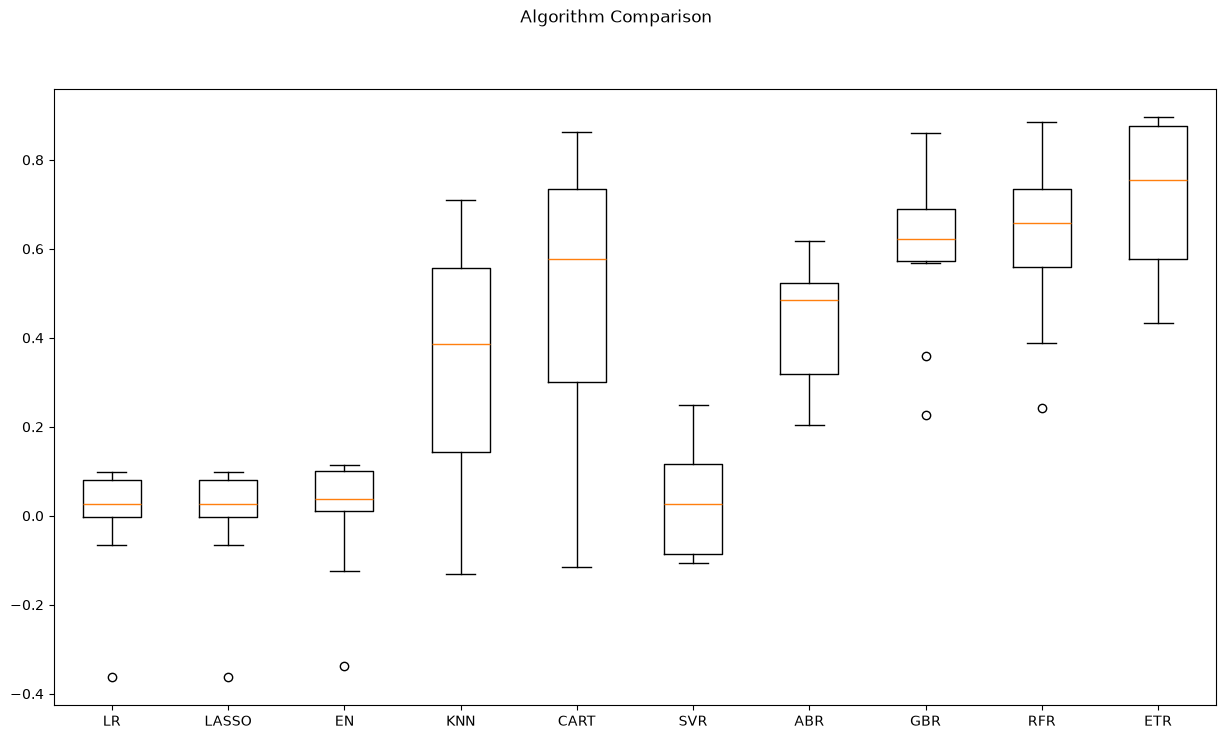

In [52]:
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
fig.set_size_inches(15,8)
plt.show()

In [ ]:
'''  
= LR, LASSO, EN : 선형 회귀 계열 
- 그래프를 보면 중앙값이 거의 0에 가까움
- 이 모델에서는 현재 변수들로 TrueRiskTolerance를 선형적인 관계만으로 설명하는 데 한계가 있다는 것을 보여줌
- 현재 가지고 있는 변수들을 이용해서 직선 형태의 수학적 관계만으로 TrueRiskTolerance를 예측하기 어려움

= KNN(K-Nearest Neighbors)
- 주변에 있는 비슷한 데이터들의 값을 이용해 예측

= CART (Decision Tree)
- 의사결정 나무 모델
* KNN과 CART의 성능은 특정 데이터 분할에서는 좋은 성능을 보이지만 다른 분할에서는 성능이 낮아질 수 있음
* RFR: 여러 결정트리의 예측을 평균하여 개별 트리의 불안정성을 줄일 수 있음

= SVR(Support Vector Regression)
- 회귀 문제에 서포트 벡터 머신을 적용한 모델
- 비선형 관계도 학습할 수 있지만, 현재 그래프에서는 성능 낮음
- 나쁜 알고리즘은 아님
- 변수의 스케일에 민감하므로 표준화가 필수여야함(하이퍼파라미터, 데이터 전처리, 스케일링)

= ABR, GBR, RFR, ETR
- 상대적으로 성능이 높음, 앙상블(Ensemble) 계열
- ETR은 중앙값이 약 0.77로 가장 높음
- GBR과 RFR도 중앙값이 약 0.64로 높은 편

* 개별 변수의 단순한 선형 관계보다는 여러 변수의 조합과 복잡한 패턴을 학습하는 모델이 이번 데이터에서 유리할 가능성을 보여줌 

= Tree 모델 정리
AdaBoost Regressor: 이전 모델의 오차를 보완하면서 학습
Gradient Boosting Regressor : 잔차를 줄이는 방향으로 순차 학습
Random Forest Regressor	: 여러 결정트리의 예측을 평균, 부트스트랩 샘플링
Extra Trees Regressor : 무작위성을 더 많이 활용하는 여러 결정트리의 앙상블, 전체 데이터 한꺼번에 씀
'''

In [ ]:
''' 
비선형 모델이 선형 모델보다 좋은 성능
이는 위험 감수 성향과 이를 예측하는 변수들 사이에 비선형 관계가 있음을 시사
랜덤 포레스트 회귀가 우수한 방법 중 하나 - 이 모델을 기준으로 그리드 탐색을 진행
'''

* 모델 튜닝과 그리드 탐색

In [53]:
param_grid = {'n_estimators': [50,100,150,200,250,300,350,400]}   # 랜덤 포레스트를 구성하는 결정 트리의 개수
model = RandomForestRegressor()
kfold = KFold(n_splits=num_folds)
grid = GridSearchCV(estimator=model, param_grid=param_grid, scoring=scoring, cv=kfold)

grid_result = grid.fit(X_train, Y_train)
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.641732 using {'n_estimators': 400}
0.628062 (0.214070) with: {'n_estimators': 50}
0.639449 (0.215269) with: {'n_estimators': 100}
0.634694 (0.208171) with: {'n_estimators': 150}
0.637810 (0.208110) with: {'n_estimators': 200}
0.639571 (0.198044) with: {'n_estimators': 250}
0.630601 (0.207440) with: {'n_estimators': 300}
0.639776 (0.208693) with: {'n_estimators': 350}
0.641732 (0.200303) with: {'n_estimators': 400}


* 최종 모델 확정 :  {'n_estimators': 400}


* 테스트 데이터셋 평가 결과

In [54]:
# 최종 모델 구성 및 학습
model = RandomForestRegressor(n_estimators = 400)
model.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [55]:
# 결정계수를 계산
from sklearn.metrics import r2_score

predictions_train = model.predict(X_train)
print(r2_score(Y_train, predictions_train))

0.9608233277888302


In [56]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

predictions = model.predict(X_validation)
print(mean_squared_error(Y_validation, predictions))
print(r2_score(Y_validation, predictions))

0.018292391695545755
0.785103694536832


In [ ]:
'''
r2_score :  모델의 설명력
MSE : 예측 오차
0.96 - 0.78 = 0.18 : 이 모델은 학습 데이터보다 검증 데이터의 설명력이 약 0.18 정도 낮음 
'''

In [ ]:
# 특성 중요도와 특성 해석

[0.17787142 0.02223167 0.01317895 0.08536567 0.0392194  0.16768576
 0.07002524 0.42442188]


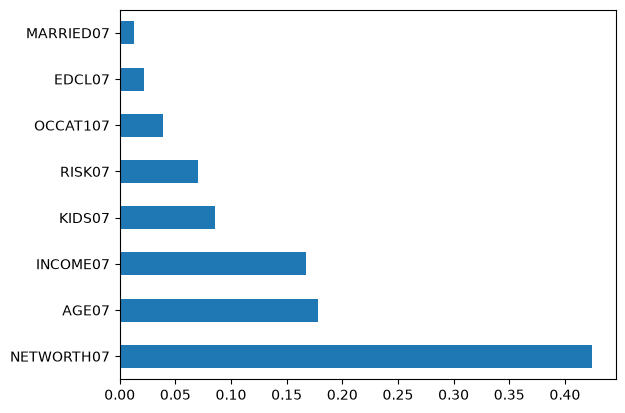

In [ ]:
print(model.feature_importances_) 
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh')
plt.show()

# 금융 위험 선호도(NETWORTH07), 연령(Age), 순자산(INCOME07)이 위험 감수 성향을 결정하는 핵심 변수

In [ ]:
# 추후 사용을 위한 모델 저장

In [58]:
from pickle import dump
from pickle import load

filename = 'finalized_model.sav'
dump(model, open(filename, 'wb'))

In [59]:
# 모델 삭제
del model

In [61]:
# 디스크에 저장된 모델 불러오기
loaded_model = load(open(filename, 'rb'))

predictions = loaded_model.predict(X_validation)
result = mean_squared_error(Y_validation, predictions)
print(r2_score(Y_validation, predictions))
print(result)

0.785103694536832
0.018292391695545755


* 결론

In [ ]:
'''   
- 머신러닝 모델로 변화하는 시장에서(2008년 금융 위기) 다양한 투자자의 행동을 객관적으로 분석
- 그 변화를 위험 감수 성향 결정에 관련된 변수들과 연결할 수 있음을 보여줌
- 투자자 데이터가 증가하고 머신러닝 인프라가 풍부해지면 이러한 모델의 활용 가치도 높아질 수 있음

- 변수들과 위험 감수 성향 사이에는 비선형 관계가 있음
    * 소득과 순자산이 주요 변수
    * 연령과 위험을 감수하려는 의지가 중요
    * 여러 문헌에서도 이런 변수들을 위험 감수 성향 모델링의 핵심 변수로 다루고 있음 
'''